# PCD Assignment 03
## Image Segmentation and Morphological Processing

Nama: `Tenno Cahyo Berliantoko`  
NIM: `25/568393/PA/23995`

### Tujuan
1. Melakukan segmentasi citra menggunakan metode global thresholding Otsu.
2. Mengimplementasikan operasi morfologi biner dilation, erosion, opening, closing, hit and miss Transform, Thinning, Thickening, dan skeleton.
3. Membandingkan hasil segmentasi sebelum dan sesudah pemrosesan morfologi.

### Ketentuan implementasi
- Perhitungan histogram, threshold Otsu, segmentasi biner, dan operasi morfologi dibuat menggunakan perulangan Python.
- Pillow (`PIL`) hanya digunakan untuk membaca/konversi/menyimpan gambar, sedangkan Matplotlib hanya untuk menampilkan hasil.

### Alur pengerjaan
Input gambar → Grayscale → Otsu Thresholding → Binary Segmentation → Morphological Operations → Comparison



## 1. Import library dan pengaturan gambar

Upload gambar ke Google Colab, kemudian salin path gambarnya ke variabel `IMAGE_PATH` di bawah. Contoh path: `/content/gambar_saya.jpg`.

hanya perlu mengganti `IMAGE_PATH` dan, bila perlu, `FOREGROUND`:
- `"bright"`: objek/area foreground dianggap lebih terang dari background.
- `"dark"`: objek/area foreground dianggap lebih gelap dari background.

`MAX_IMAGE_SIDE` membatasi sisi terpanjang gambar agar proses manual tidak terlalu lama. Gunakan `None` jika ingin mempertahankan ukuran asli.


In [4]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

IMAGE_PATH = "/content/20260327114112792_DZQX5PGY.jpg"

# Pilih "bright" untuk objek terang atau "dark" untuk objek gelap
FOREGROUND = "bright"

# Ukuran maksimum sisi terpanjang gambar.
# Isi None jika tidak ingin mengubah ukuran gambar.
MAX_IMAGE_SIDE = 600

# Structuring element 3x3 (semua elemen aktif / bernilai 1)
STRUCTURING_ELEMENT = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
]

# Urutan operasi untuk hasil akhir perbandingan.
# Opening membantu menghilangkan noise foreground kecil,
# sedangkan closing membantu mengisi lubang/celah kecil.
MORPHOLOGY_SEQUENCE = ["opening", "closing"]

# Folder tempat hasil akan disimpan
OUTPUT_DIR = "/content"

if FOREGROUND not in ("bright", "dark"):
    raise ValueError('FOREGROUND harus bernilai "bright" atau "dark".')

image_path = Path(IMAGE_PATH)
if not image_path.is_file():
    raise FileNotFoundError(
        f"Gambar tidak ditemukan: {IMAGE_PATH}\n"
        "Periksa kembali IMAGE_PATH. Di Google Colab, upload gambar lalu salin path-nya."
    )

# Membaca gambar dan mengubahnya menjadi grayscale menggunakan PIL.
input_image = Image.open(image_path).convert("L")
original_size = input_image.size

# Resize opsional agar implementasi manual lebih cepat.
if MAX_IMAGE_SIDE is not None:
    width, height = input_image.size
    longest_side = max(width, height)
    if longest_side > MAX_IMAGE_SIDE:
        scale = MAX_IMAGE_SIDE / longest_side
        new_size = (max(1, int(width * scale)), max(1, int(height * scale)))
        input_image = input_image.resize(new_size, Image.Resampling.LANCZOS)

width, height = input_image.size

# Mengubah gambar menjadi list 2D Python (tanpa NumPy).
gray_image = [[input_image.getpixel((x, y)) for x in range(width)] for y in range(height)]

print(f"Path gambar       : {IMAGE_PATH}")
print(f"Ukuran asli       : {original_size[0]} x {original_size[1]} pixel")
print(f"Ukuran pemrosesan : {width} x {height} pixel")
print(f"Mode foreground   : {FOREGROUND}")


Path gambar       : /content/20260327114112792_DZQX5PGY.jpg
Ukuran asli       : 800 x 513 pixel
Ukuran pemrosesan : 600 x 384 pixel
Mode foreground  : bright


## 2. Menampilkan gambar grayscale

Gambar diubah menjadi grayscale agar setiap pixel memiliki intensitas 0-255. Nilai 0 adalah hitam dan 255 adalah putih.


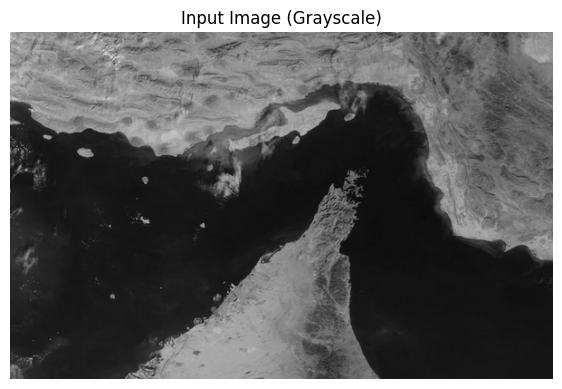

In [5]:
plt.figure(figsize=(7, 5))
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Input Image (Grayscale)")
plt.axis("off")
plt.show()


## 3. Segmentasi menggunakan Otsu Thresholding

Otsu memilih nilai threshold berdasarkan histogram intensitas grayscale. Setiap intensitas diuji untuk memperoleh pemisahan dua kelompok pixel dengan variansi antar-kelas terbesar.

Setelah threshold ditemukan, pixel diklasifikasikan menjadi:
- `1` (foreground/putih) jika memenuhi kondisi foreground yang dipilih.
- `0` (background/hitam) selain itu.

Seluruh perhitungan histogram dan pencarian threshold dilakukan dengan Python.


In [18]:
# Membuat histogram grayscale (256 tingkat intensitas).
def make_histogram(gray):
    histogram = [0] * 256
    for row in gray:
        for pixel in row:
            histogram[pixel] += 1
    return histogram


def otsu_threshold(gray):
    histogram = make_histogram(gray)
    total_pixels = sum(histogram)
    total_intensity = 0

    for intensity in range(256):
        total_intensity += intensity * histogram[intensity]

    background_weight = 0
    background_sum = 0
    maximum_between_variance = -1
    best_threshold = 0

    for threshold in range(256):
        background_weight += histogram[threshold]
        if background_weight == 0:
            continue

        foreground_weight = total_pixels - background_weight
        if foreground_weight == 0:
            break

        background_sum += threshold * histogram[threshold]
        mean_background = background_sum / background_weight
        mean_foreground = (total_intensity - background_sum) / foreground_weight

        between_variance = (background_weight * foreground_weight * (mean_background - mean_foreground) ** 2)

        if between_variance > maximum_between_variance:
            maximum_between_variance = between_variance
            best_threshold = threshold

    return best_threshold

threshold_value = otsu_threshold(gray_image)

def threshold_segmentation(gray, threshold, foreground="bright"):
    binary = []
    for row in gray:
        binary_row = []
        for pixel in row:
            if foreground == "bright":
                binary_row.append(1 if pixel > threshold else 0)
            else:
                binary_row.append(1 if pixel <= threshold else 0)
        binary.append(binary_row)
    return binary

segmented_image = threshold_segmentation( gray_image, threshold_value, FOREGROUND )

print(f"Nilai threshold Otsu: {threshold_value}")
print(f"Jumlah pixel       : {width * height:,}")


Nilai threshold Otsu: 78
Jumlah pixel       : 230,400


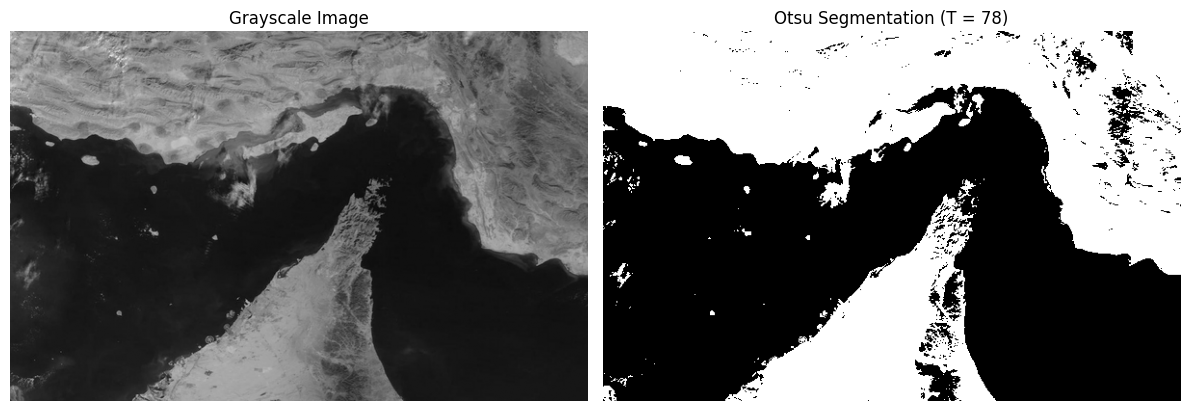

In [7]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image, cmap="gray", vmin=0, vmax=1)
plt.title(f"Otsu Segmentation (T = {threshold_value})")
plt.axis("off")
plt.tight_layout()
plt.show()


## 4. Implementasi operasi morfologi secara manual

Structuring element (SE) yang digunakan adalah matriks 3×3 dengan origin di pixel tengah.

- Dilation: pixel output menjadi foreground jika minimal satu posisi SE yang aktif bertemu foreground.
- Erosion: pixel output tetap foreground hanya jika seluruh posisi SE yang aktif bertemu foreground.
- Opening: erosion kemudian dilation menggunakan SE yang sama.
- Closing: dilation kemudian erosion menggunakan SE yang sama.

Untuk pixel yang berada di luar batas gambar, nilainya dianggap background (0).


In [8]:
# Mengambil koordinat elemen aktif pada structuring element.
def get_active_kernel_positions(kernel):
    if not kernel or not kernel[0]:
        raise ValueError("Structuring element tidak boleh kosong.")

    kernel_height = len(kernel)
    kernel_width = len(kernel[0])

    if kernel_height % 2 == 0 or kernel_width % 2 == 0:
        raise ValueError("Ukuran structuring element harus ganjil, misalnya 3x3.")

    for row in kernel:
        if len(row) != kernel_width:
            raise ValueError("Semua baris structuring element harus sama panjang.")

    origin_y = kernel_height // 2
    origin_x = kernel_width // 2
    active_positions = []

    for ky in range(kernel_height):
        for kx in range(kernel_width):
            if kernel[ky][kx] == 1:
                active_positions.append((ky - origin_y, kx - origin_x))

    if not active_positions:
        raise ValueError("Structuring element harus memiliki minimal satu nilai 1.")

    return active_positions


def binary_dilation(binary, kernel):
    height = len(binary)
    width = len(binary[0])
    active_positions = get_active_kernel_positions(kernel)
    result = [[0 for _ in range(width)] for _ in range(height)]
    for y in range(height):
        for x in range(width):
            # Cukup satu tetangga foreground untuk menghasilkan foreground.
            for dy, dx in active_positions:
                ny, nx = y + dy, x + dx
                if 0 <= ny < height and 0 <= nx < width:
                    if binary[ny][nx] == 1:
                        result[y][x] = 1
                        break
    return result


def binary_erosion(binary, kernel):
    height = len(binary)
    width = len(binary[0])
    active_positions = get_active_kernel_positions(kernel)
    result = [[0 for _ in range(width)] for _ in range(height)]

    for y in range(height):
        for x in range(width):
            keep_pixel = True
            for dy, dx in active_positions:
                ny, nx = y + dy, x + dx
                if not (0 <= ny < height and 0 <= nx < width):
                    keep_pixel = False
                    break
                if binary[ny][nx] == 0:
                    keep_pixel = False
                    break
            if keep_pixel:
                result[y][x] = 1
    return result


def binary_opening(binary, kernel):
    eroded = binary_erosion(binary, kernel)
    return binary_dilation(eroded, kernel)


def binary_closing(binary, kernel):
    dilated = binary_dilation(binary, kernel)
    return binary_erosion(dilated, kernel)

print("fungsi morfologi berhasil didefinisikan.")


Semua fungsi morfologi manual berhasil didefinisikan.


## 5. Menjalankan setiap operasi morfologi

Di bagian ini setiap operasi ditampilkan secara terpisah agar efeknya dapat diamati dan dibandingkan dengan hasil segmentasi awal.


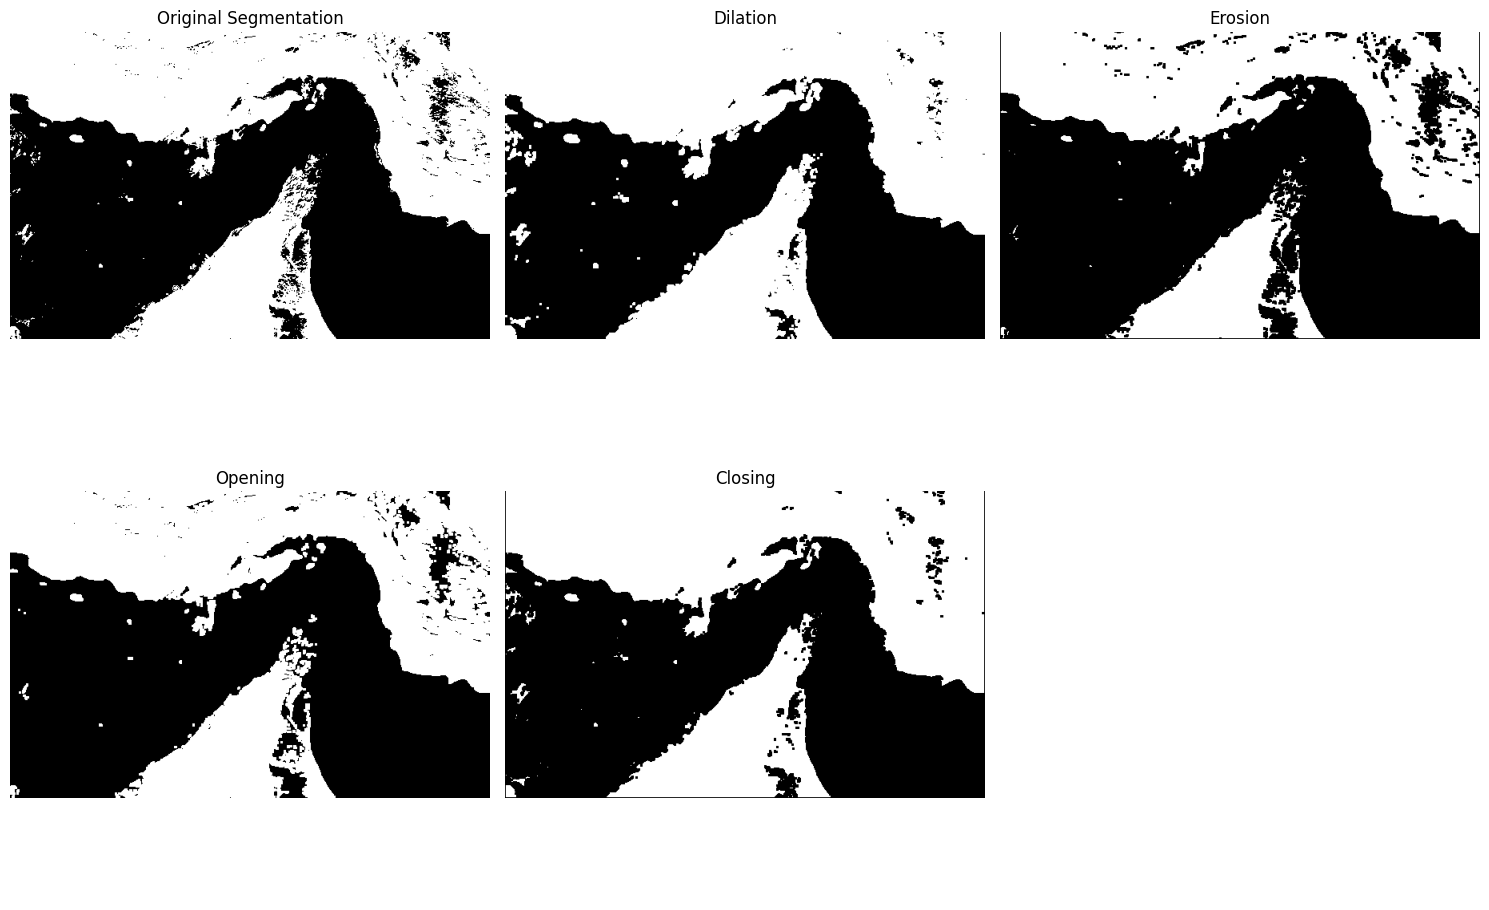

In [9]:
dilated_image = binary_dilation(segmented_image, STRUCTURING_ELEMENT)
eroded_image = binary_erosion(segmented_image, STRUCTURING_ELEMENT)
opened_image = binary_opening(segmented_image, STRUCTURING_ELEMENT)
closed_image = binary_closing(segmented_image, STRUCTURING_ELEMENT)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
images = [
    (segmented_image, "Original Segmentation"),
    (dilated_image, "Dilation"),
    (eroded_image, "Erosion"),
    (opened_image, "Opening"),
    (closed_image, "Closing"),
]

for ax, (img, title) in zip(axes.flat, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

axes.flat[5].axis("off")
plt.tight_layout()
plt.show()


## 6. Membandingkan segmentasi sebelum dan sesudah morfologi

Untuk hasil akhir, operasi pada `MORPHOLOGY_SEQUENCE` diterapkan berurutan pada hasil segmentasi. Pengaturan awal menggunakan opening → closing.

Perbandingan kuantitatif yang ditampilkan adalah jumlah pixel foreground, persentase foreground, dan jumlah pixel yang berubah. Nilai ini menunjukkan perubahan bentuk/luas area, bukan akurasi klasifikasi.


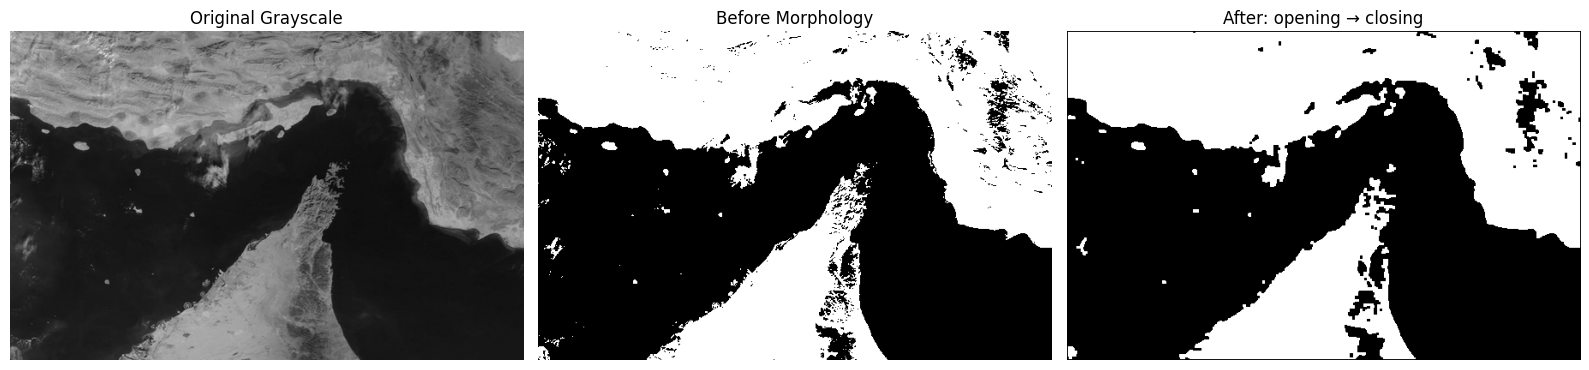

========== COMPARISON ==========
Threshold Otsu                 : 78
Morphology sequence            : opening -> closing
Total pixels                   : 230,400
Foreground before morphology   : 103,677 (45.00%)
Foreground after morphology    : 101,236 (43.94%)
Changed pixels                 : 5,025 (2.18%)


In [10]:
# Menerapkan urutan operasi yang dipilih.
processed_image = segmented_image

for operation in MORPHOLOGY_SEQUENCE:
    if operation == "dilation":
        processed_image = binary_dilation(processed_image, STRUCTURING_ELEMENT)
    elif operation == "erosion":
        processed_image = binary_erosion(processed_image, STRUCTURING_ELEMENT)
    elif operation == "opening":
        processed_image = binary_opening(processed_image, STRUCTURING_ELEMENT)
    elif operation == "closing":
        processed_image = binary_closing(processed_image, STRUCTURING_ELEMENT)
    else:
        raise ValueError(f"Operasi morfologi tidak dikenal: {operation}")


def count_foreground(binary):
    total = 0
    for row in binary:
        for pixel in row:
            if pixel == 1:
                total += 1
    return total


def count_changed_pixels(image_a, image_b):
    changed = 0
    for y in range(len(image_a)):
        for x in range(len(image_a[0])):
            if image_a[y][x] != image_b[y][x]:
                changed += 1
    return changed


total_pixels = width * height
foreground_before = count_foreground(segmented_image)
foreground_after = count_foreground(processed_image)
changed_pixels = count_changed_pixels(segmented_image, processed_image)

ratio_before = 100 * foreground_before / total_pixels
ratio_after = 100 * foreground_after / total_pixels
changed_ratio = 100 * changed_pixels / total_pixels

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")
axes[1].imshow(segmented_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Before Morphology")
axes[2].imshow(processed_image, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("After: " + " → ".join(MORPHOLOGY_SEQUENCE))
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("COMPARISON")
print(f"Threshold Otsu                 : {threshold_value}")
print(f"Morphology sequence            : {' -> '.join(MORPHOLOGY_SEQUENCE)}")
print(f"Total pixels                   : {total_pixels:,}")
print(f"Foreground before morphology   : {foreground_before:,} ({ratio_before:.2f}%)")
print(f"Foreground after morphology    : {foreground_after:,} ({ratio_after:.2f}%)")
print(f"Changed pixels                 : {changed_pixels:,} ({changed_ratio:.2f}%)")


## 7. Advanced Morphological Operations

Bagian ini menambahkan empat operasi morfologi lanjutan, yaitu Hit-and-Miss Transform, Thinning, Thickening, dan Skeletonization. Semua operasi bekerja pada citra biner hasil segmentasi Otsu (`segmented_image`) dan diimplementasikan menggunakan list serta perulangan Python.

Implementasi ini menggunakan fungsi `binary_erosion()` dan `binary_opening()` yang sudah didefinisikan pada bagian sebelumnya. Tidak diperlukan input gambar atau proses segmentasi ulang.

### 7.1 Hit-and-Miss Transform

Hit-and-Miss Transform digunakan untuk mendeteksi pola tertentu pada citra biner dengan mencocokkan foreground dan background sekaligus. Pattern/structuring element menggunakan tiga jenis nilai:

- `1`: posisi tersebut harus merupakan foreground (putih).
- `0`: posisi tersebut harus merupakan background (hitam).
- `-1`: posisi tersebut tidak diperiksa (*don't care*).

Pixel output bernilai 1 apabila seluruh kondisi pada pattern cocok dengan citra di sekitar posisi tersebut. Pada contoh ini, pattern digunakan untuk mendeteksi pola batas objek dengan arah tertentu.

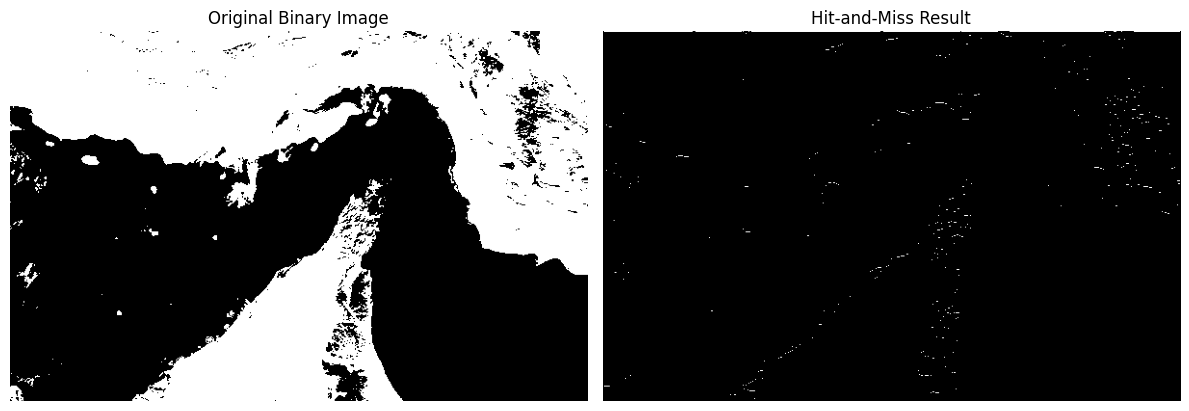

Jumlah pola yang terdeteksi: 1066


In [11]:
def advanced_hit_and_miss(binary, pattern):
    if not binary or not binary[0]:
        raise ValueError("Citra biner tidak boleh kosong.")
    if not pattern or not pattern[0]:
        raise ValueError("Pattern tidak boleh kosong.")

    height = len(binary)
    width = len(binary[0])
    pattern_height = len(pattern)
    pattern_width = len(pattern[0])

    if pattern_height % 2 == 0 or pattern_width % 2 == 0:
        raise ValueError("Ukuran pattern harus ganjil, misalnya 3x3.")
    if any(len(row) != pattern_width for row in pattern):
        raise ValueError("Semua baris pattern harus memiliki panjang yang sama.")
    if any(len(row) != width for row in binary):
        raise ValueError("Semua baris citra harus memiliki panjang yang sama.")
    if any(value not in (0, 1, -1) for row in pattern for value in row):
        raise ValueError("Pattern hanya boleh berisi 1, 0, dan -1.")

    origin_y = pattern_height // 2
    origin_x = pattern_width // 2
    result = [[0 for _ in range(width)] for _ in range(height)]

    for y in range(height):
        for x in range(width):
            matched = True

            for py in range(pattern_height):
                for px in range(pattern_width):
                    required = pattern[py][px]

                    # -1 berarti posisi ini tidak perlu diperiksa.
                    if required == -1:
                        continue

                    ny = y + py - origin_y
                    nx = x + px - origin_x

                    # Pixel di luar batas citra dianggap background (0).
                    if 0 <= ny < height and 0 <= nx < width:
                        actual = binary[ny][nx]
                    else:
                        actual = 0

                    if actual != required:
                        matched = False
                        break

                if not matched:
                    break

            if matched:
                result[y][x] = 1

    return result


HIT_MISS_PATTERN = [
    [0,  0,  0],
    [-1, 1, -1],
    [1,  1,  1]
]

hit_miss_image = advanced_hit_and_miss( segmented_image, HIT_MISS_PATTERN )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(segmented_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Binary Image")
axes[1].imshow(hit_miss_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Hit-and-Miss Result")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah pola yang terdeteksi:", count_foreground(hit_miss_image))

### 7.2 Thinning

Thinning menghapus pixel foreground tertentu secara bertahap sehingga objek menjadi lebih tipis, dengan tetap berusaha mempertahankan bentuk dan konektivitas utamanya.

Implementasi berikut menggunakan **Zhang-Suen thinning**, yaitu algoritma thinning berbasis pemeriksaan tetangga 8-arah. Setiap iterasi terdiri dari dua sub-iterasi penghapusan pixel. Seluruh pemeriksaan tetangga dan penghapusan pixel dilakukan secara manual menggunakan perulangan Python.

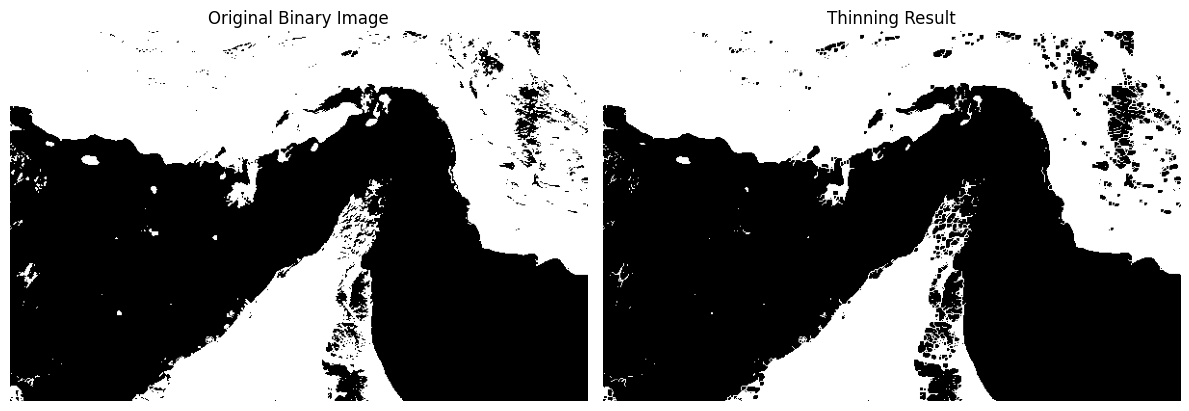

Jumlah iterasi thinning: 1
Foreground sebelum thinning: 103677
Foreground sesudah thinning: 96877


In [27]:
def advanced_thinning(binary, max_iterations=5):
    if not binary or not binary[0]:
        raise ValueError("Citra biner tidak boleh kosong.")

    height = len(binary)
    width = len(binary[0])
    if any(len(row) != width for row in binary):
        raise ValueError("Semua baris citra harus memiliki panjang yang sama.")

    image = [row[:] for row in binary]
    iterations_done = 0

    for iteration in range(max_iterations):
        changed_in_iteration = False

        # Dua sub-iterasi dengan kondisi penghapusan yang berbeda.
        for sub_iteration in (0, 1):
            pixels_to_delete = []
            # Border luar tidak diproses agar tidak terjadi akses indeks di luar citra.
            for y in range(1, height - 1):
                for x in range(1, width - 1):
                    if image[y][x] != 1:
                        continue

                    # Tetangga berurutan searah jarum jam: P2 sampai P9.
                    p2 = image[y - 1][x]
                    p3 = image[y - 1][x + 1]
                    p4 = image[y][x + 1]
                    p5 = image[y + 1][x + 1]
                    p6 = image[y + 1][x]
                    p7 = image[y + 1][x - 1]
                    p8 = image[y][x - 1]
                    p9 = image[y - 1][x - 1]

                    neighbors = [p2, p3, p4, p5, p6, p7, p8, p9]
                    neighbor_count = sum(neighbors)

                    # Jumlah transisi 0 ke 1 pada urutan melingkar P2...P9.
                    transitions = 0
                    for index in range(8):
                        current_value = neighbors[index]
                        next_value = neighbors[(index + 1) % 8]
                        if current_value == 0 and next_value == 1:
                            transitions += 1

                    if not (2 <= neighbor_count <= 6):
                        continue
                    if transitions != 1:
                        continue

                    if sub_iteration == 0:
                        condition_1 = (p2 * p4 * p6 == 0)
                        condition_2 = (p4 * p6 * p8 == 0)
                    else:
                        condition_1 = (p2 * p4 * p8 == 0)
                        condition_2 = (p2 * p6 * p8 == 0)

                    if condition_1 and condition_2:
                        pixels_to_delete.append((y, x))

            # Hapus pixel setelah satu sub-iterasi selesai.
            for y, x in pixels_to_delete:
                image[y][x] = 0

            if pixels_to_delete:
                changed_in_iteration = True

        iterations_done = iteration + 1
        if not changed_in_iteration:
            break

    return image, iterations_done

thinned_image, thinning_iterations = advanced_thinning( segmented_image, max_iterations=1 )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(segmented_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Binary Image")
axes[1].imshow(thinned_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Thinning Result")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah iterasi thinning:", thinning_iterations)
print("Foreground sebelum thinning:", count_foreground(segmented_image))
print("Foreground sesudah thinning:", count_foreground(thinned_image))

### 7.3 Thickening

Thickening merupakan operasi yang menambahkan pixel foreground pada lokasi tertentu di sekitar objek sehingga area objek bertambah tebal. Operasi ini merupakan dual dari thinning: citra dikomplemenkan, thinning diterapkan pada komplemennya, kemudian hasilnya dikomplemenkan kembali.

Parameter `max_iterations` mengatur banyaknya iterasi penebalan. Jumlah iterasi yang terlalu besar dapat menyebabkan objek membesar secara berlebihan.

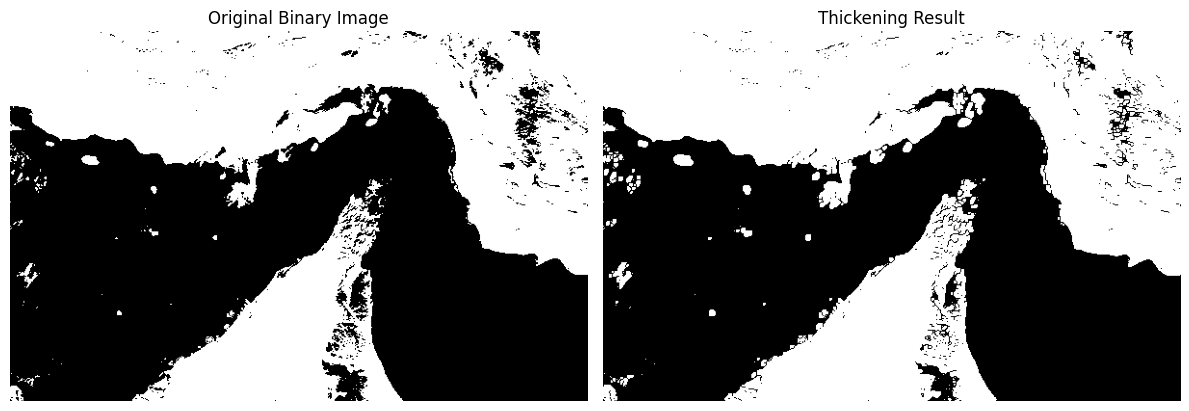

Jumlah iterasi thickening: 1
Foreground sebelum thickening: 103677
Foreground sesudah thickening: 109452


In [22]:
def advanced_complement(binary):
    return [[1 - pixel for pixel in row] for row in binary]


def advanced_thickening(binary, max_iterations=1):
    background_image = advanced_complement(binary)
    thinned_background, _ = advanced_thinning(
        background_image,
        max_iterations=max_iterations
    )
    return advanced_complement(thinned_background)


THICKENING_ITERATIONS = 1
thickened_image = advanced_thickening( segmented_image, max_iterations=THICKENING_ITERATIONS)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(segmented_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Binary Image")
axes[1].imshow(thickened_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Thickening Result")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah iterasi thickening:", THICKENING_ITERATIONS)
print("Foreground sebelum thickening:", count_foreground(segmented_image))
print("Foreground sesudah thickening:", count_foreground(thickened_image))

### 7.4 Skeletonization

Skeletonization adalah proses mereduksi area foreground menjadi kerangka yang merepresentasikan bentuk utama objek. Kerangka diharapkan mempertahankan informasi bentuk dan konektivitas objek dengan jumlah pixel yang lebih sedikit.

Implementasi berikut menggunakan pendekatan morphological skeleton. Pada setiap iterasi, citra yang sedang diproses dierosi, kemudian dilakukan opening. Selisih antara citra sebelum opening dan hasil opening ditambahkan ke skeleton. Proses berulang pada hasil erosi hingga foreground habis atau tidak ada perubahan.

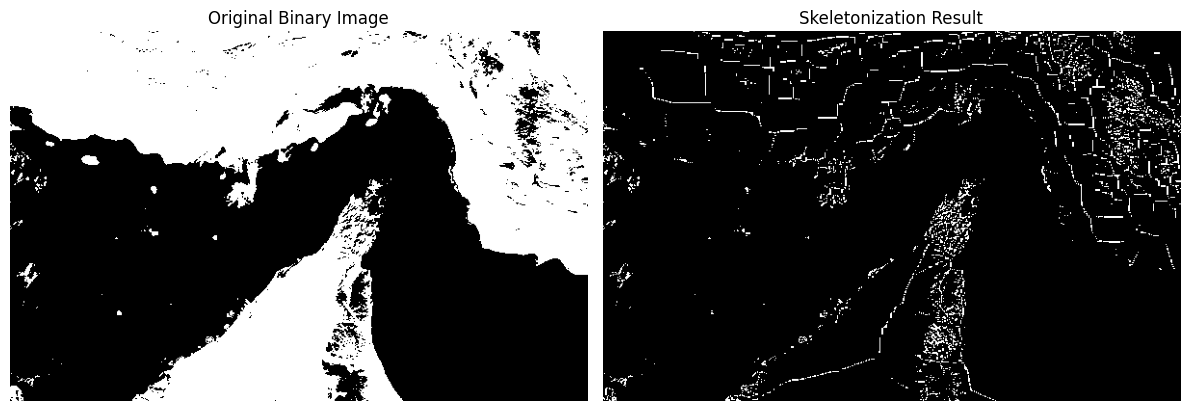

Jumlah iterasi skeletonization: 43
Foreground sebelum skeletonization: 103677
Foreground pada skeleton: 8731


In [34]:
def advanced_skeleton(binary, kernel, max_iterations=200):
    if not binary or not binary[0]:
        raise ValueError("Citra biner tidak boleh kosong.")

    height = len(binary)
    width = len(binary[0])
    current = [row[:] for row in binary]
    skeleton = [[0 for _ in range(width)] for _ in range(height)]
    iterations_done = 0

    for iteration in range(max_iterations):
        if count_foreground(current) == 0:
            break

        # A_k dikurangi opening(A_k), lalu hasilnya digabung ke skeleton.
        opened = binary_opening(current, kernel)
        for y in range(height):
            for x in range(width):
                if current[y][x] == 1 and opened[y][x] == 0:
                    skeleton[y][x] = 1

        # Erosi membentuk A_(k+1) untuk iterasi berikutnya.
        eroded = binary_erosion(current, kernel)
        iterations_done = iteration + 1

        if eroded == current:
            break
        current = eroded
    return skeleton, iterations_done

skeleton_image, skeleton_iterations = advanced_skeleton(segmented_image, STRUCTURING_ELEMENT,max_iterations=100)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(segmented_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Binary Image")
axes[1].imshow(skeleton_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Skeletonization Result")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah iterasi skeletonization:", skeleton_iterations)
print("Foreground sebelum skeletonization:", count_foreground(segmented_image))
print("Foreground pada skeleton:", count_foreground(skeleton_image))

### 7.5 Perbandingan hasil advanced morphological operations

Bagian ini menampilkan hasil keempat operasi lanjutan berdampingan dengan citra segmentasi awal. Jumlah pixel foreground juga dicetak untuk membantu mengamati perubahan luas area. Nilai tersebut merupakan perbandingan jumlah pixel, bukan ukuran akurasi.

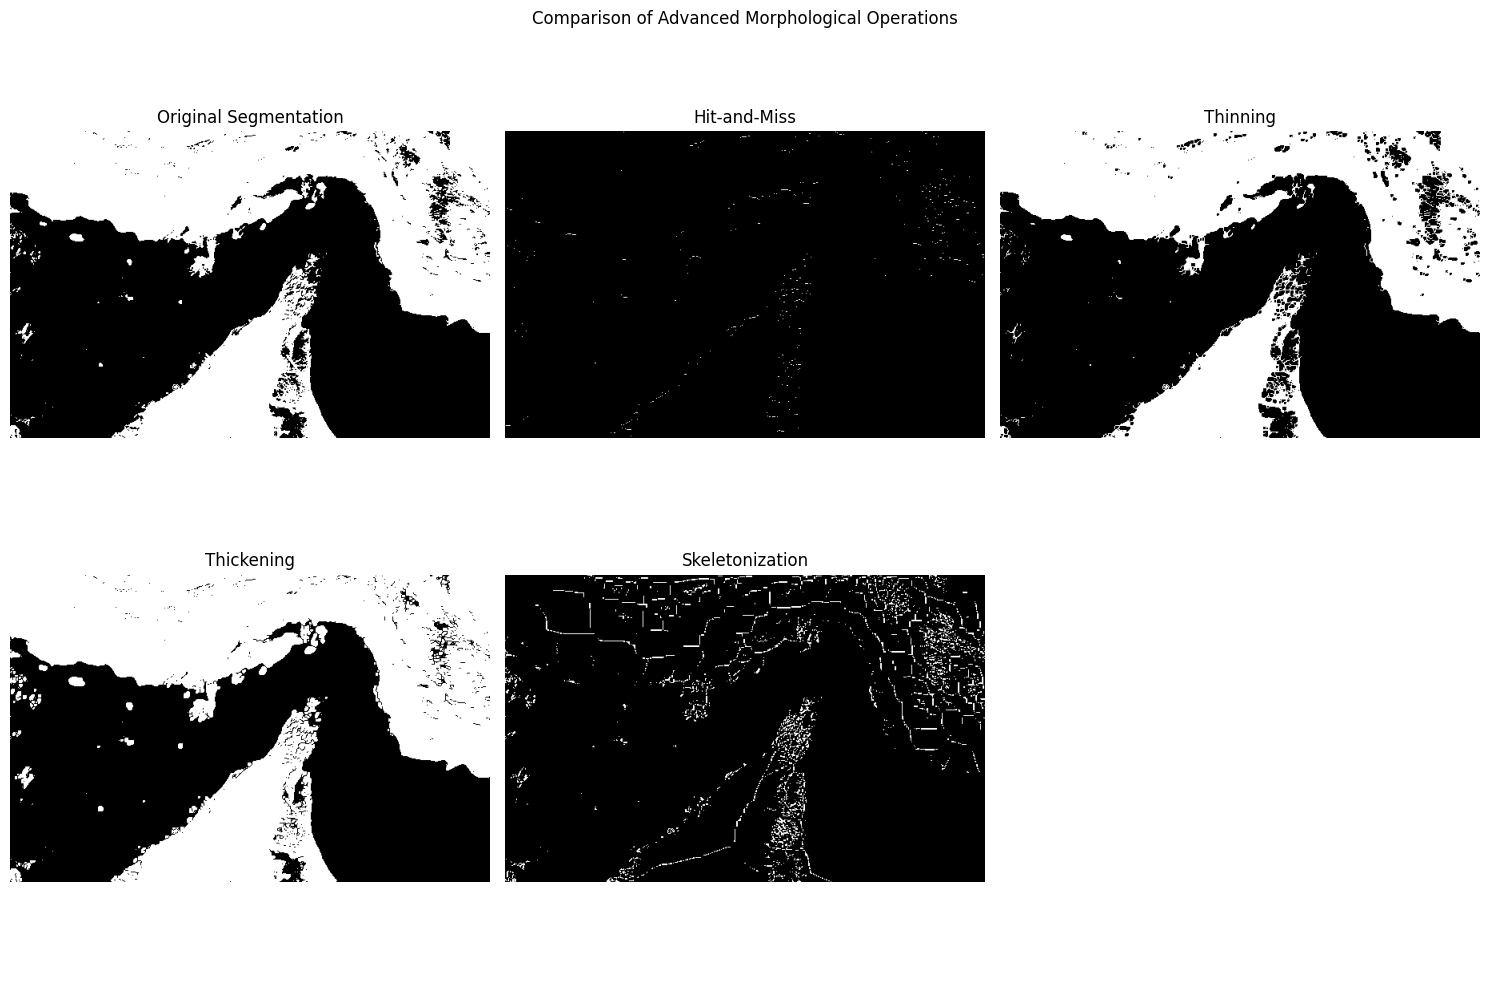

ADVANCED MORPHOLOGICAL OPERATIONS - PIXEL COMPARISON
Operation                     Foreground pixels       Percentage
------------------------------------------------------------------
Original Segmentation                   103,677           45.00%
Hit-and-Miss                              1,066            0.46%
Thinning                                 96,877           42.05%
Thickening                              109,452           47.51%
Skeletonization                           8,731            3.79%


In [35]:
advanced_operation_results = [
    ("Original Segmentation", segmented_image),
    ("Hit-and-Miss", hit_miss_image),
    ("Thinning", thinned_image),
    ("Thickening", thickened_image),
    ("Skeletonization", skeleton_image),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (title, result_image) in zip(axes.flat, advanced_operation_results):
    ax.imshow(result_image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
axes.flat[5].axis("off")
plt.suptitle("Comparison of Advanced Morphological Operations")
plt.tight_layout()
plt.show()


print("ADVANCED MORPHOLOGICAL OPERATIONS - PIXEL COMPARISON")
print(f"{'Operation':<25}{'Foreground pixels':>22}{'Percentage':>17}")
print("-" * 66)
for operation_name, result_image in advanced_operation_results:
    foreground_count = count_foreground(result_image)
    foreground_percentage = 100 * foreground_count / total_pixels
    print(
        f"{operation_name:<25}{foreground_count:>22,}"
        f"{foreground_percentage:>16.2f}%"
    )

## 8. Kesimpulan dan Analisis Hasil

### A. Analisis hasil segmentasi

Segmentasi dilakukan menggunakan Otsu Thresholding, yaitu metode yang menentukan nilai ambang berdasarkan histogram grayscale dengan mencari pemisahan dua kelompok intensitas yang memiliki variansi antar-kelas maksimum. Nilai threshold yang diperoleh digunakan untuk mengubah citra grayscale menjadi citra biner.

- Jika `FOREGROUND = "bright"`, pixel dengan intensitas lebih besar dari threshold menjadi foreground (putih), sedangkan sisanya menjadi background (hitam).
- Jika `FOREGROUND = "dark"`, pixel dengan intensitas lebih kecil atau sama dengan threshold menjadi foreground, sedangkan sisanya menjadi background.

### B. Analisis operasi morfologi

Keempat operasi morfologi menggunakan structuring element (SE) 3×3 yang sama. Pengaruhnya terhadap citra biner adalah sebagai berikut.

1. Dilation memperbesar atau memperluas area foreground. Operasi ini dapat menyambungkan bagian objek yang berdekatan dan memperkecil celah kecil, tetapi juga dapat membuat objek yang berdekatan menyatu.
2. Erosion memperkecil area foreground. Operasi ini dapat memisahkan objek yang menempel atau menghilangkan bagian foreground yang tipis, tetapi jika terlalu kuat dapat menghilangkan detail objek.
3. Opening merupakan erosion yang dilanjutkan dengan dilation menggunakan SE yang sama. Operasi ini cenderung menghilangkan noise atau bagian foreground kecil, sambil mempertahankan bentuk objek yang ukurannya sesuai dengan SE.
4. **Closing** merupakan dilation yang dilanjutkan dengan erosion menggunakan SE yang sama. Operasi ini cenderung menutup lubang kecil dan menyambungkan celah sempit pada area foreground.

### C. Perbandingan sebelum dan sesudah morfologi

Hasil segmentasi awal dibandingkan dengan hasil setelah urutan operasi pada `MORPHOLOGY_SEQUENCE` diterapkan. Jumlah dan persentase pixel foreground menunjukkan perubahan luas area objek. Jumlah pixel yang berubah menunjukkan seberapa banyak posisi pixel yang berbeda antara kedua citra biner.

jumlah foreground yang bertambah atau berkurang tidak otomatis berarti hasil segmentasi menjadi lebih akurat. Penilaian kualitas tetap perlu dilakukan dengan melihat citra hasil. Jika tersedia ground-truth mask, kualitas dapat dievaluasi lebih lanjut menggunakan metrik seperti Precision, Recall, F1-score, atau IoU.



### D. Kesimpulan operasi morfologi lanjutan

Berdasarkan hasil yang ditampilkan, kesimpulan setiap operasi adalah:

1. Hit-and-Miss Transform mendeteksi posisi yang sesuai dengan pola foreground dan background pada pattern. Hasil deteksi bergantung pada pola yang dipilih.
2. Thinning mengurangi pixel pada bagian tepi objek secara bertahap agar objek menjadi lebih tipis. Hasilnya dapat digunakan untuk melihat struktur utama objek.
3. Thickening menambahkan pixel foreground sehingga area objek menjadi lebih tebal. Banyaknya perubahan dipengaruhi oleh jumlah iterasi.
4. Skeletonization menghasilkan representasi kerangka objek melalui pengulangan erosion, opening, dan penggabungan selisih citra.

## 9. Menyimpan hasil akhir

Tiga file hasil akan disimpan pada folder `OUTPUT_DIR`:
- `PCD_Assignment03_grayscale.png`
- `PCD_Assignment03_segmentation_before.png`
- `PCD_Assignment03_segmentation_after.png`

Gambar biner dikonversi dari nilai 0/1 menjadi intensitas 0/255 sebelum disimpan.


In [17]:
def binary_to_pil(binary):
    height = len(binary)
    width = len(binary[0])
    output = Image.new("L", (width, height))
    pixels = output.load()
    for y in range(height):
        for x in range(width):
            pixels[x, y] = 255 if binary[y][x] == 1 else 0
    return output


output_folder = Path(OUTPUT_DIR)
output_folder.mkdir(parents=True, exist_ok=True)

grayscale_output = input_image
before_output = binary_to_pil(segmented_image)
after_output = binary_to_pil(processed_image)

saved_files = [
    output_folder / "PCD_Assignment03_grayscale.png",
    output_folder / "PCD_Assignment03_segmentation_before.png",
    output_folder / "PCD_Assignment03_segmentation_after.png",
]

grayscale_output.save(saved_files[0])
before_output.save(saved_files[1])
after_output.save(saved_files[2])

print("File berhasil disimpan:")
for file_path in saved_files:
    print(file_path)


File berhasil disimpan:
/content/PCD_Assignment03_grayscale.png
/content/PCD_Assignment03_segmentation_before.png
/content/PCD_Assignment03_segmentation_after.png
